# The banking game and the captaincy race

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, '.')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import data, model, sim, bank, milp
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'lines.linewidth': 1.6, 'font.size': 9})
os.makedirs('figs', exist_ok=True)
save = lambda fig, nm: [fig.savefig(f'figs/{nm}.{ext}', bbox_inches='tight') for ext in ['pdf', 'png']]

## The banking game

The two-week worked example from `docs/math.md` section 1: with the menu $g = (1, 6)$ (the second transfer worth more than the first) the value of a banked transfer goes up rather than down and the best number of transfers jumps by two; with $g = (6, 1)$ everything behaves.

In [2]:
bank.counterexample()

(1, 6) [3. 7. 7.] [ 7. 10. 14.] [0 2 2]
(6, 1) [6. 7. 7.] [12. 13. 14.] [1 1 2]


[None, None]

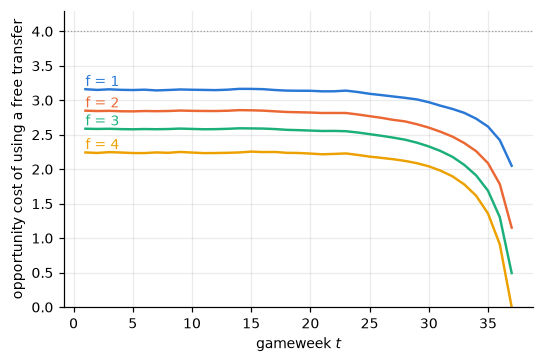

In [3]:
# marginal value of a banked transfer next week, V_{t+1}(f+1) - V_{t+1}(f), under iid exponential menus
V = bank.solve(bank.expo_menu(2.0), n=4000)
fig, ax = plt.subplots(figsize=(5.5, 3.5))
for f in range(1, 5):
    y = [V[t + 1][f] - V[t + 1][f - 1] for t in range(1, 38)]
    ax.plot(range(1, 38), y, color=C[f - 1])
    ax.text(1, y[0], f'f = {f}', color=C[f - 1], va='bottom', ha='left')
ax.axhline(4, color='0.6', lw=0.8, ls=':')
ax.set_xlabel('gameweek $t$'); ax.set_ylabel('opportunity cost of using a free transfer'); ax.set_ylim(0, 4.3)
save(fig, 'bank_thresholds')

The value of a banked transfer is never above 4 (it saves at most one hit, so it is worth at most 4 points), zero at the cap, smaller the more you hold (shown here, not proved), and falls to zero at the end of the season when a banked transfer has no future.

In [4]:
# the same with the empirical menus the MILP produced along the myopic path
bt = pd.read_csv('data/cache/backtest.csv')
g = bt[bt.policy == 'h1'][['g1', 'g2', 'g3']].dropna().clip(lower=0).values
print('menus', len(g), 'mean', g.mean(0).round(2))
emp = lambda rng, n: -np.sort(-g[rng.integers(0, len(g), n)], 1)   # sorting imposes the menu assumption, which about half the menus break
for K, col in [(5, C[0]), (2, C[1])]:
    Vk = bank.solve(emp, K=K, n=4000)
    print('K', K, 'V_1', Vk[1].round(1), 'marginal at gw 10', np.diff(Vk[11]).round(2))
    print(' opportunity cost table kappa(f, j) at gw 10'); print(bank.kappa(Vk[11], K=K).round(2))

menus 185 mean [2.41 2.03 1.57]
K 5 V_1 [132.  134.7 137.  139.1 140.7] marginal at gw 10 [2.71 2.37 2.02 1.69]
 opportunity cost table kappa(f, j) at gw 10
[[2.71 4.   4.   4.  ]
 [2.37 2.71 4.   4.  ]
 [2.02 2.37 2.71 4.  ]
 [1.69 2.02 2.37 2.71]
 [0.   1.69 2.02 2.37]]
K 2 V_1 [119.9 121.9] marginal at gw 10 [2.08]
 opportunity cost table kappa(f, j) at gw 10
[[2.08 4.   4.   4.  ]
 [0.   2.08 4.   4.  ]]


## Captaincy in a two-manager race

You hold the model's best squad, the rival holds the most-owned squad and captains its best forecast. Win probability as a function of the lead $L$ before the gameweek, for captaining the same player as the rival (low variance) versus your best alternative, from 40,000 simulated gameweeks. Dashed lines are the normal approximation and the vertical line is the threshold $L^*$, the lead at which matching the rival's captain and picking a differential give equal win probability.

In [5]:
from scipy.stats import norm
QUOTA = [2, 5, 5, 3]
rows = []
for s, t in [('2023-24', 20), ('2024-25', 12), ('2025-26', 30), ('2022-23', 8)]:
    p, *_ = model.bundle(s)
    xp, info = model.forecast(s, t)
    own = data.wide(p, 'selected')[t].reindex(xp.index).fillna(0)
    Y = model.simulate(s, t, n=40000, seed=1)
    pick = lambda sc: sum([list(sc[info.pos == q].nlargest(QUOTA[q]).index) for q in range(4)], [])
    mine, rival = pick(xp[t]), pick(own)
    xi, cap, vice, _ = sim.lineup(xp.loc[mine, t], info.pos[mine])
    xi_r, j, _, _ = sim.lineup(xp.loc[rival, t], info.pos[rival])
    c = [i for i in [cap, vice] if i != j][0]
    B, Br = Y[xi].sum(axis=1).values, Y[xi_r].sum(axis=1).values + Y[j].values
    D0 = B + Y[j].values * (j in xi) - Br
    D1 = B + Y[c].values - Br
    mu0, s0, mu1, s1 = D0.mean(), D0.std(), D1.mean(), D1.std()
    Lstar = (mu1 - mu0) * s0 / (s1 - s0) - mu0
    for L in range(-40, 41):
        rows.append(dict(season=s, t=t, j=info.name[j], c=info.name[c], L=L, p_same=(L + D0 > 0).mean(), p_diff=(L + D1 > 0).mean(),
                         g_same=norm.cdf((L + mu0) / s0), g_diff=norm.cdf((L + mu1) / s1), Lstar=Lstar, j_in_xi=j in xi))
t4 = pd.DataFrame(rows)
t4.to_csv('data/cache/t4.csv', index=False)
for (s, t), g in t4.groupby(['season', 't']):
    cross = g.L[g.p_same >= g.p_diff].min()
    print(s, t, g.j.iloc[0][:16], 'vs', g.c.iloc[0][:16], '| L* = %.1f, simulated crossing = %d' % (g.Lstar.iloc[0], cross))

2022-23 8 Nick Pope vs Son Heung-min | L* = -6.7, simulated crossing = -6
2023-24 20 Erling Haaland vs Mohamed Salah | L* = -7.0, simulated crossing = -6
2024-25 12 Cole Palmer vs Mohamed Salah | L* = -5.0, simulated crossing = -4
2025-26 30 Erling Haaland vs Mohamed Salah | L* = -0.4, simulated crossing = -1


[None, None]

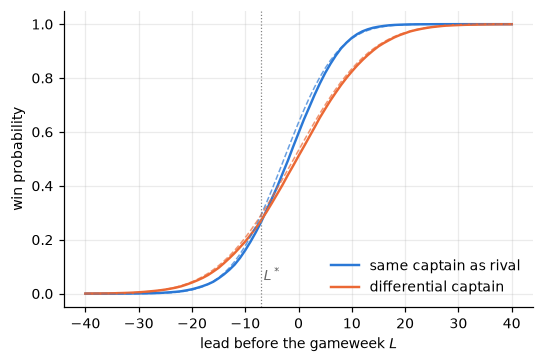

In [6]:
g = t4[(t4.season == '2023-24')]
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(g.L, g.p_same, color=C[0], label='same captain as rival')
ax.plot(g.L, g.p_diff, color=C[1], label='differential captain')
ax.plot(g.L, g.g_same, color=C[0], ls='--', lw=1, alpha=0.7)
ax.plot(g.L, g.g_diff, color=C[1], ls='--', lw=1, alpha=0.7)
ax.axvline(g.Lstar.iloc[0], color='0.5', lw=0.8, ls=':')
ax.text(g.Lstar.iloc[0] + 0.5, 0.05, '$L^*$', color='0.4')
ax.set_xlabel('lead before the gameweek $L$'); ax.set_ylabel('win probability'); ax.legend(frameon=False, loc='lower right')
save(fig, 'captaincy')